In [2]:
import numpy as np
import matplotlib.pyplot as plt

In [35]:
def hit_z(h, R):
    return R - np.sqrt(R ** 2 - h ** 2)
def refract_flat(h, R, n1, n2):
    alpha = (np.arcsin(h / R))
    print(np.degrees(alpha))
    theta2 = np.arcsin((n1 * np.sin(alpha)) / n2)
    print(np.degrees(theta2))
    u = -(alpha - theta2)
    return np.tan(u)

m = refract_flat(6, 25, 1.0, 1.5)

13.88654036262899
9.2068962213459


In [ ]:
def hit_z(h, R):
    return R - np.sqrt(R ** 2 - h ** 2)
def refract_flat(h, R, n1, n2):
    alpha = (np.arcsin(h / R))
    theta2 = np.arcsin((n1 * np.sin(alpha)) / n2)
    u = -(alpha - theta2)
    return np.tan(u)

def crossing(h, R, n1, n2):
    m = refract_flat(h, R, n1, n2)
    return hit_z(h, R) - h / m

print(crossing(6, 25, 1.0, 1.5))
print(1.5 * 25 / (1.5 - 1.0)) # checking with textbook methof

74.02896818942592
75.0


In [18]:
h = np.arange(1, 11)
print(np.round(crossing(h, 25, 1.0, 1.5), 2))

[74.97 74.89 74.76 74.57 74.33 74.03 73.67 73.26 72.78 72.24]


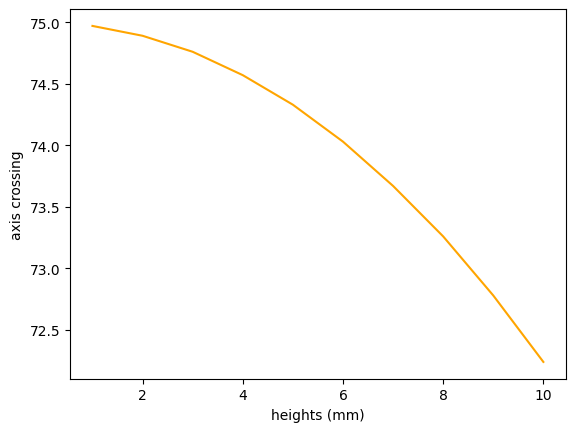

In [31]:
h = np.arange(1, 11)
values = np.round(crossing(h, 25, 1.0, 1.5), 2)
plt.plot(h, values, color = "orange")
plt.xlabel("heights (mm)")
plt.ylabel("axis crossing")
plt.show()

- outer rays have a normal that tilts more, not “closer”.
- theta2 gets bigger too, not smaller. Check your own numbers: θ₂ goes 0.027 -> 0.270 radians as h goes from 1 to 10.

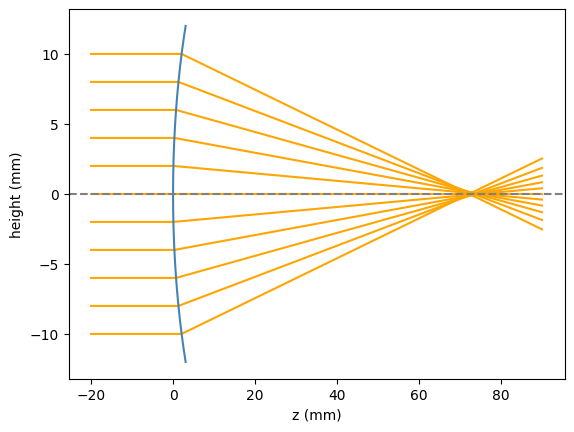

In [33]:
heights = np.linspace(-10, 10, 11)
R = 25
n2 = 1.5
z_end = 90
for h in heights:
    z1 = hit_z(h, R)
    m = refract_flat(h, R, 1.0, n2)
    plt.plot([-20, z1, z_end], [h, h, h + m * (z_end - z1)], color = "orange")

ys = np.linspace(-12, 12, 200)
plt.plot(R - np.sqrt(R ** 2 - ys ** 2), ys, color = "steelblue")
plt.axhline(color = "grey", linestyle = "--")
plt.xlabel("z (mm)")
plt.ylabel("height (mm)")
plt.show()

- most of the rays cross the z-line at around 72-75, and they are spread from 72 - 75 (the rays near the axis).
- that smear is the blue -> the spot size.

150.0


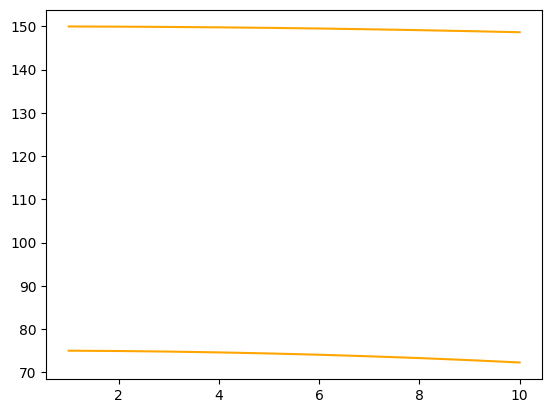

In [30]:
R = 50
print(1.5 * R / (1.5 - 1.0)) # textbook f
h = np.arange(1, 11)
values50 = np.round(crossing(h, R, 1.0, 1.5), 2)
values25 = np.round(crossing(h, 25, 1.0, 1.5), 2)
plt.plot(h, values50, color = "orange")
plt.plot(h, values25, color = "orange")
plt.show()

In [36]:
spread25 = crossing(1, 25, 1.0, 1.5) - crossing(10, 25, 1.0, 1.5)
spread50 = crossing(1, 50, 1.0, 1.5) - crossing(10, 50, 1.0, 1.5)
print(spread25 / 75 * 100, "%")
print(spread50 / 150 * 100, "%")

2.292442775955887
1.5280685946107546
23.578178478201835
15.466009953420551
1.1459919983885924
0.7639663640218032
11.536959032815489
7.662255660766065
3.6391435490828217 %
0.88703650376245 %


- a bigger R (R = 50) means a flatter surface, so its normals tilt less. so, with the same ray heights (1 to 10), every ray hits at a smaller angle -> where snell's law behaves almost like the "straight-line rule", so the rays all bend "in proportion" and land close together.
- what designers need is a short focus (75 vs 150) AND gentle curves (to keep light rays sharp). my guess is, using different lenses, so that there are more gentle surfaces to bend the light to keep the light rays sharp and focus less.